# Figure 1: 2D obstacle course

Reproduces Fig. 1(a) and 1(c): the four lowest-pressure paths through the hardware obstacle course, and their predicted growth pressure versus deployed length.

The course is a grid of 6 in voxels, 6 wide and 5 deep, with four rows of walls. Each row has a few openings. Every path must pass through one opening per row, so we solve each combination of openings (a *route*) separately and rank them by pressure.

Runtime: about a minute (most of it is Numba compiling on first use).

In [1]:
import sys; sys.path.insert(0, "..")   # use the repo's vine_planner without pip install

import itertools
import numpy as np
import matplotlib.pyplot as plt

from vine_planner.obstacle_course import ObstacleCourseVoxels
from vine_planner.path_planner import PathPlanner
from vine_planner.utils import pressure_profile, pressure_conversion

PSI_TO_KPA = pressure_conversion("psi", "kpa")
IN_TO_M = 0.0254

## Course

`OPEN[row]` lists the open positions (1 to 6, left to right) in each wall row. Everything else in that row is a wall. The start is in the corner of row 0 farthest from position 1; the end is the opposite corner of row 5.

In [2]:
VOXEL, UNITS = 6.0, "in"          # voxel size, and what the coordinates mean
NX, NZ = 6, 5                     # voxels wide, voxels deep (one voxel tall)
WIDTH, HEIGHT, DEPTH = NX * VOXEL, VOXEL, NZ * VOXEL
BURST_KPA = 25.0                  # hypothetical burst pressure (dashed line)

OPEN = {1: (1, 3), 2: (1, 4, 6), 3: (2, 6), 4: (4, 6)}

START = np.array([WIDTH, HEIGHT / 2, 0.0])
END = np.array([0.0, HEIGHT / 2, DEPTH])


def walls(open_positions):
    """One wall (voxel i, j, k, face) for every closed position; face 4 is -z."""
    return [
        (column, 0, row, 4)
        for row, positions in open_positions.items()
        for column in range(NX)
        if column + 1 not in positions
    ]

## Solve every route

Walling off every opening except one per row leaves exactly one way through, so the planner returns the best path for that route.

In [3]:
results = []
for route in itertools.product(*OPEN.values()):
    course = ObstacleCourseVoxels(
        width=WIDTH, height=HEIGHT, depth=DEPTH, voxel_size=VOXEL,
        obstacles=walls({row: (gap,) for row, gap in zip(OPEN, route)}),
    )
    planner = PathPlanner(course, start=START, end=END, length_units=UNITS)
    path = planner.compute_pressure_path()
    results.append((planner.total_pressure * PSI_TO_KPA, route, path))

results.sort(key=lambda r: r[0])
PARAMS = planner.model_parameters

for rank, (pressure, route, _) in enumerate(results, start=1):
    print(f"{rank:>2}. {pressure:6.2f} kPa   route {route}")

 1.  24.33 kPa   route (3, 4, 6, 4)
 2.  24.97 kPa   route (3, 1, 2, 4)
 3.  25.32 kPa   route (3, 4, 6, 6)
 4.  26.05 kPa   route (1, 1, 2, 4)
 5.  29.06 kPa   route (3, 6, 6, 4)
 6.  30.24 kPa   route (3, 6, 6, 6)
 7.  31.51 kPa   route (1, 4, 6, 4)
 8.  32.79 kPa   route (1, 4, 6, 6)
 9.  34.31 kPa   route (3, 1, 2, 6)
10.  34.42 kPa   route (3, 1, 6, 4)
11.  35.70 kPa   route (1, 6, 6, 4)
12.  35.79 kPa   route (1, 1, 2, 6)
13.  35.81 kPa   route (3, 1, 6, 6)
14.  35.92 kPa   route (1, 1, 6, 4)
15.  37.13 kPa   route (1, 6, 6, 6)
16.  37.37 kPa   route (1, 1, 6, 6)
17.  39.05 kPa   route (3, 4, 2, 4)
18.  53.78 kPa   route (3, 4, 2, 6)
19.  80.98 kPa   route (1, 4, 2, 4)
20.  99.99 kPa   route (3, 6, 2, 4)
21. 111.78 kPa   route (1, 4, 2, 6)
22. 124.21 kPa   route (1, 6, 2, 4)
23. 138.08 kPa   route (3, 6, 2, 6)
24. 171.58 kPa   route (1, 6, 2, 6)


## The four paths in the paper

In [4]:
PAPER_ROUTES = [(3, 4, 6, 4), (3, 4, 6, 6), (1, 1, 2, 4), (3, 6, 6, 4)]
COLORS = ["tab:green", "tab:blue", "tab:orange", "tab:red"]
LABELS = ["Best", "2nd", "3rd", "4th"]

by_route = {route: (pressure, route, path) for pressure, route, path in results}
shown = [by_route[route] for route in PAPER_ROUTES]

### Fig. 1(a): paths, seen from above

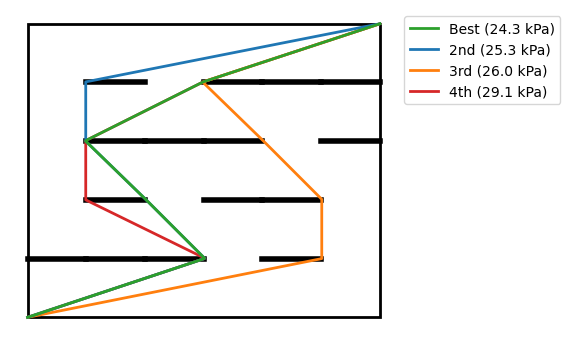

In [5]:
fig, ax = plt.subplots(figsize=(5, 4.5))
ax.add_patch(plt.Rectangle((0, 0), WIDTH, DEPTH, fill=False, lw=2))
for row, positions in OPEN.items():
    for column in range(NX):
        if column + 1 not in positions:
            ax.plot([column * VOXEL, (column + 1) * VOXEL], [row * VOXEL] * 2, "k", lw=4)

for i, ((pressure, route, path), color, label) in enumerate(zip(shown, COLORS, LABELS)):
    ax.plot(path[:, 0], path[:, 2], color=color, lw=2, zorder=10 - i, label=f"{label} ({pressure:.1f} kPa)")

ax.invert_xaxis()   # match the orientation of the photo
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### Fig. 1(c): pressure vs. deployed length

Each vertical jump is a turn: it multiplies all the tension accumulated so far.

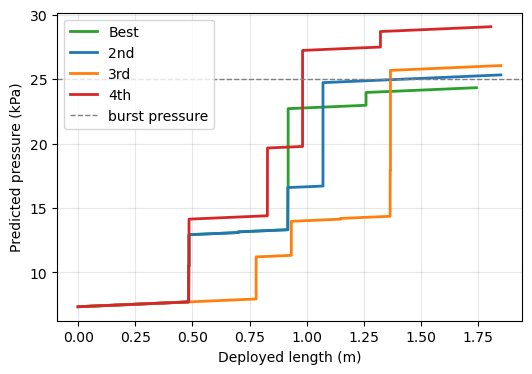

In [6]:
fig, ax = plt.subplots(figsize=(6, 4))
for (pressure, route, path), color, label in zip(shown, COLORS, LABELS):
    s, p = pressure_profile(path, length_units=UNITS, **PARAMS)
    ax.plot(s * IN_TO_M, p * PSI_TO_KPA, color=color, lw=2, label=label)
ax.axhline(BURST_KPA, color="gray", ls="--", lw=1, label="burst pressure")
ax.set_xlabel("Deployed length (m)")
ax.set_ylabel("Predicted pressure (kPa)")
ax.grid(alpha=0.3)
ax.legend()
plt.show()